In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)
# Model Development
RANDOM_STATE = 42

In [2]:
df = pd.read_csv(
    r"D:\loan_Risk_Assesment\Data\loan_risk_dataset_1000_rows.csv"
)

print(df["Loan_Risk"].value_counts(dropna=False))

Loan_Risk
High    818
Low     177
NaN       5
Name: count, dtype: int64


In [3]:
df.shape

(1000, 10)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Loan_Application_ID   1000 non-null   str    
 1   Name                  1000 non-null   str    
 2   Age                   982 non-null    float64
 3   Monthly_Income        979 non-null    float64
 4   Loan_Amount           988 non-null    float64
 5   Loan_Term_Months      1000 non-null   int64  
 6   Credit_Score          977 non-null    float64
 7   Previous_Defaults     987 non-null    float64
 8   Monthly_Debt_Payment  984 non-null    float64
 9   Loan_Risk             995 non-null    str    
dtypes: float64(6), int64(1), str(3)
memory usage: 100.6 KB


In [5]:
df.columns

Index(['Loan_Application_ID', 'Name', 'Age', 'Monthly_Income', 'Loan_Amount',
       'Loan_Term_Months', 'Credit_Score', 'Previous_Defaults',
       'Monthly_Debt_Payment', 'Loan_Risk'],
      dtype='str')

In [6]:
df.describe()

,Age,Monthly_Income,Loan_Amount,Loan_Term_Months,Credit_Score,Previous_Defaults,Monthly_Debt_Payment
count,982.000000,9.790000e+02,9.880000e+02,1000.000000,977.000000,987.000000,984.000000
mean,41.089613,6.490988e+04,5.665787e+05,47.560000,681.925281,0.622087,17483.142276
std,12.960542,9.808917e+04,4.846540e+05,24.336776,106.888250,1.208505,43750.547244
min,-5.000000,-1.000000e+04,-1.000000e+05,-12.000000,-50.000000,-3.000000,-5000.000000
25%,30.250000,4.207900e+04,3.083588e+05,24.000000,601.000000,0.000000,7523.000000
50%,42.000000,5.855900e+04,5.638655e+05,48.000000,681.000000,0.000000,13140.000000
75%,51.750000,8.048050e+04,7.659265e+05,72.000000,766.000000,1.000000,20921.500000
max,150.000000,2.500000e+06,1.000000e+07,150.000000,1100.000000,20.000000,1000000.000000


In [7]:
df.isnull().sum()

Loan_Application_ID      0
Name                     0
Age                     18
Monthly_Income          21
Loan_Amount             12
Loan_Term_Months         0
Credit_Score            23
Previous_Defaults       13
Monthly_Debt_Payment    16
Loan_Risk                5
dtype: int64

In [8]:
df.duplicated().sum()
df["Loan_Application_ID"].duplicated().sum()

np.int64(8)

In [9]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [10]:
df["Name"] = df["Name"].astype(str).str.strip().str.title()

In [11]:
df.loc[(df["Age"] < 18) | (df["Age"] > 80), "Age"] = np.nan

In [12]:
df.loc[(df["Credit_Score"] < 300) | (df["Credit_Score"] > 900), "Credit_Score"] = np.nan
df.loc[df["Previous_Defaults"] < 0, "Previous_Defaults"] = np.nan
df[["Monthly_Income", "Loan_Amount", "Monthly_Debt_Payment"]].describe()


,Monthly_Income,Loan_Amount,Monthly_Debt_Payment
count,9.790000e+02,9.880000e+02,984.000000
mean,6.490988e+04,5.665787e+05,17483.142276
std,9.808917e+04,4.846540e+05,43750.547244
min,-1.000000e+04,-1.000000e+05,-5000.000000
25%,4.207900e+04,3.083588e+05,7523.000000
50%,5.855900e+04,5.638655e+05,13140.000000
75%,8.048050e+04,7.659265e+05,20921.500000
max,2.500000e+06,1.000000e+07,1000000.000000


In [13]:
numeric_columns = [
    "Age",
    "Monthly_Income",
    "Loan_Amount",
    "Loan_Term_Months",
    "Credit_Score",
    "Previous_Defaults",
    "Monthly_Debt_Payment",
   
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [14]:
df = df.dropna(subset=["Loan_Risk"])

In [15]:
df.isnull().sum()

Loan_Application_ID     0
Name                    0
Age                     0
Monthly_Income          0
Loan_Amount             0
Loan_Term_Months        0
Credit_Score            0
Previous_Defaults       0
Monthly_Debt_Payment    0
Loan_Risk               0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(0)

Upto here the data preprocessing techniques is complteted,we can see there is no null values containing in our data and there is no duplicates and outliers in our data. Now we have to do Exploratory data Analysis for the data (with the help of graphs it helps us for feature engineering)

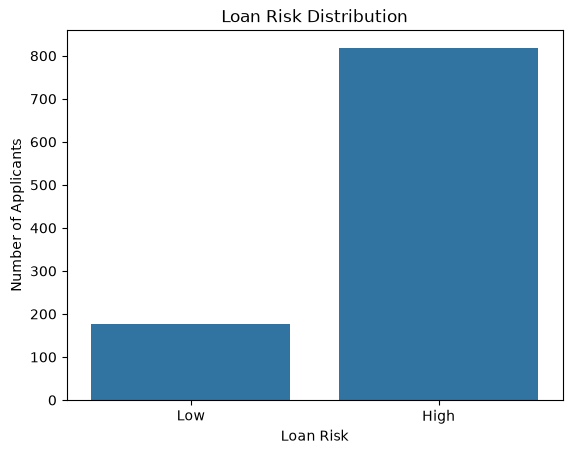

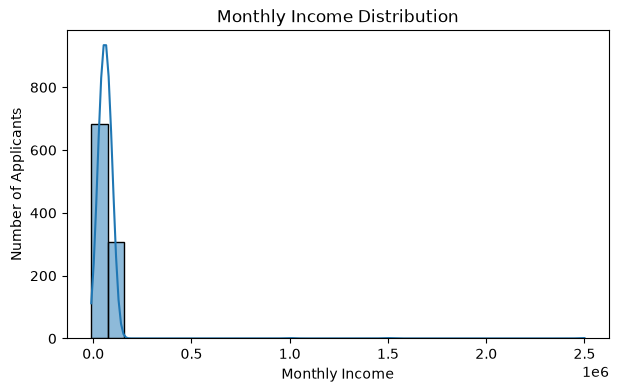

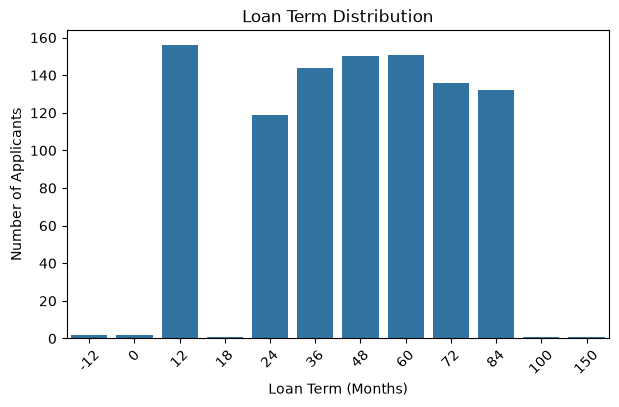

In [17]:
# we use count plot to see how many low risk and high risk applicants are there in our data
sns.countplot(x="Loan_Risk", data=df)
plt.title("Loan Risk Distribution")
plt.xlabel("Loan Risk")
plt.ylabel("Number of Applicants")
plt.show()
# we use histogram to show monthly income distribution and detect extreme income values
plt.figure(figsize=(7, 4))
sns.histplot(df["Monthly_Income"], bins=30, kde=True)
plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Applicants")
plt.show()
# here we are using again countplot to for loan term distribution to get clarity, for how many months the loan applicants are taking loan
plt.figure(figsize=(7, 4))
sns.countplot(x="Loan_Term_Months", data=df)
plt.title("Loan Term Distribution")
plt.xlabel("Loan Term (Months)")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=45)
plt.show()

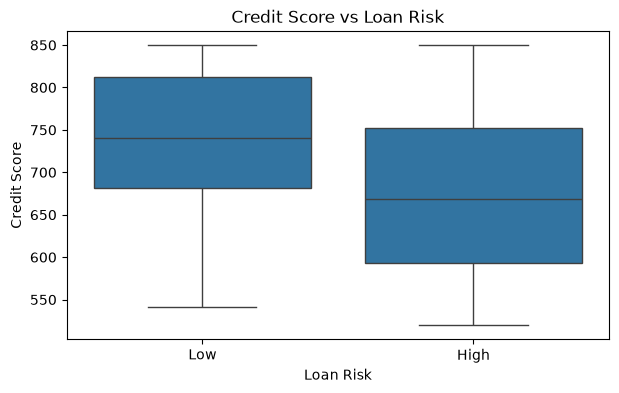

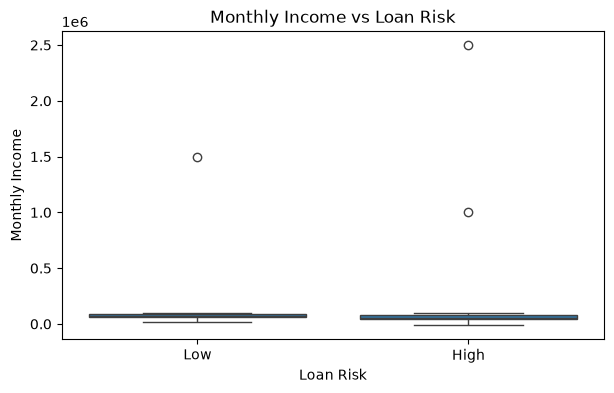

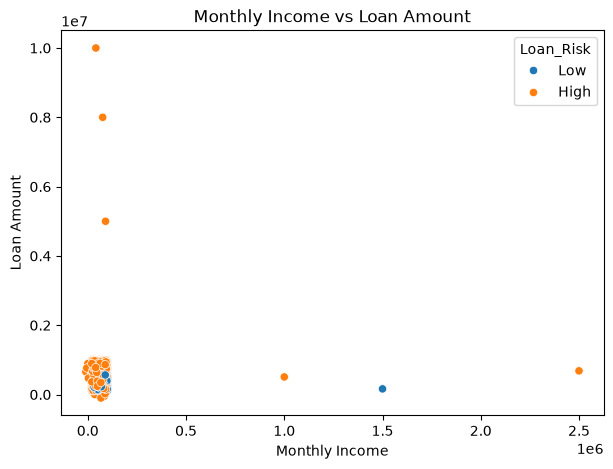

In [18]:
# here this is the main factor to analyze credit score vs loan risk
plt.figure(figsize=(7, 4))
sns.boxplot(x="Loan_Risk", y="Credit_Score", data=df)
plt.title("Credit Score vs Loan Risk")
plt.xlabel("Loan Risk")
plt.ylabel("Credit Score")
plt.show()
# here we use another boxplot to show another important analysis factor monthly income vs loan risk
plt.figure(figsize=(7, 4))
sns.boxplot(x="Loan_Risk", y="Monthly_Income", data=df)
plt.title("Monthly Income vs Loan Risk")
plt.xlabel("Loan Risk")
plt.ylabel("Monthly Income")
plt.show()
# it is also another important analysis factor loan amount vs income for numerical features
plt.figure(figsize=(7, 5))
sns.scatterplot(
    x="Monthly_Income",
    y="Loan_Amount",
    hue="Loan_Risk",
    data=df
)
plt.title("Monthly Income vs Loan Amount")
plt.xlabel("Monthly Income")
plt.ylabel("Loan Amount")
plt.show() 


In [19]:
features = [
    "Age",
    "Monthly_Income",
    "Loan_Amount",
    "Loan_Term_Months",
    "Credit_Score",
    "Previous_Defaults",
    "Monthly_Debt_Payment"
]

X = df[features]
y = df["Loan_Risk"]
# upto now the feature selection has happend now we have to do feature engineering we came with a new term Called as DTI

DTI means Debit to income Ratio : It is a comination of two factors with percentage like Monthly debt payment/monthly income * 100.

In [20]:
# Feature Engineering: Create DTI
df.loc[df["Monthly_Income"] <= 0, "Monthly_Income"] = np.nan
df.loc[df["Monthly_Debt_Payment"] < 0, "Monthly_Debt_Payment"] = np.nan
df["DTI"] = (
    df["Monthly_Debt_Payment"] / df["Monthly_Income"]
) * 100
df["DTI"].describe()

count     989.000000
mean       29.412802
std        69.994995
min         0.000000
25%        14.998610
50%        24.281035
75%        35.246967
max      1581.611135
Name: DTI, dtype: float64

In [21]:
print(df[["Monthly_Income", "Monthly_Debt_Payment", "DTI"]].head())
df["DTI"] = df["DTI"].fillna(df["DTI"].median())
print("Missing DTI after filling:", df["DTI"].isnull().sum())
print("Infinite DTI:", np.isinf(df["DTI"]).sum())

   Monthly_Income  Monthly_Debt_Payment        DTI
0         64327.0                7173.0  11.150839
1         88904.0               35959.0  40.446999
2         23797.0                5554.0  23.339076
3         67882.0               18724.0  27.583159
4         33718.0               10628.0  31.520256
Missing DTI after filling: 0
Infinite DTI: 0


In [22]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("y missing:", y.isna().sum())
print("y values:")
print(y.value_counts(dropna=False))

X shape: (995, 7)
y shape: (995,)
y missing: 0
y values:
Loan_Risk
High    818
Low     177
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

# Convert target labels
df["Loan_Risk"] = df["Loan_Risk"].map({
    "Low": 0,
    "High": 1
})

features = [
    "Age",
    "Monthly_Income",
    "Loan_Amount",
    "Loan_Term_Months",
    "Credit_Score",
    "Previous_Defaults",
    "Monthly_Debt_Payment",
    "DTI"
]

X = df[features]
y = df["Loan_Risk"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Imputation
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=features
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=features
)

# SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("After SMOTE Shape:", X_train_smote.shape)

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

print("\nSMOTE target values:")
print(sorted(pd.Series(y_train_smote).unique()))

Training Shape: (796, 8)
Testing Shape: (199, 8)
After SMOTE Shape: (1308, 8)

Before SMOTE:
Loan_Risk
1    654
0    142
Name: count, dtype: int64

After SMOTE:
Loan_Risk
1    654
0    654
Name: count, dtype: int64

SMOTE target values:
[np.int64(0), np.int64(1)]


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_smote),
    columns=features
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=features
)

print("Scaling completed.")

Scaling completed.


In [25]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42
    )
}

trained = {}

for name, model in models.items():

    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train_smote)
    else:
        model.fit(X_train_smote, y_train_smote)

    trained[name] = model

    print(f"{name} trained.")

Logistic Regression trained.


Random Forest trained.
XGBoost trained.


In [26]:
results = {}

for name, model in trained.items():

    if name == "Logistic Regression":
        X_eval = X_test_scaled
    else:
        X_eval = X_test

    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

results_df = pd.DataFrame(results).T

print(results_df.round(4))

                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8894     0.9797  0.8841    0.9295   0.9319
Random Forest          0.9196     0.9805  0.9207    0.9497   0.9641
XGBoost                0.8995     0.9800  0.8963    0.9363   0.9704


In [27]:
print("Highest Accuracy:")
print(results_df["Accuracy"].idxmax())

print("\nHighest Precision:")
print(results_df["Precision"].idxmax())

print("\nHighest Recall:")
print(results_df["Recall"].idxmax())

print("\nHighest F1-Score:")
print(results_df["F1-Score"].idxmax())

print("\nHighest ROC-AUC:")
print(results_df["ROC-AUC"].idxmax())

Highest Accuracy:
Random Forest

Highest Precision:
Random Forest

Highest Recall:
Random Forest

Highest F1-Score:
Random Forest

Highest ROC-AUC:
XGBoost


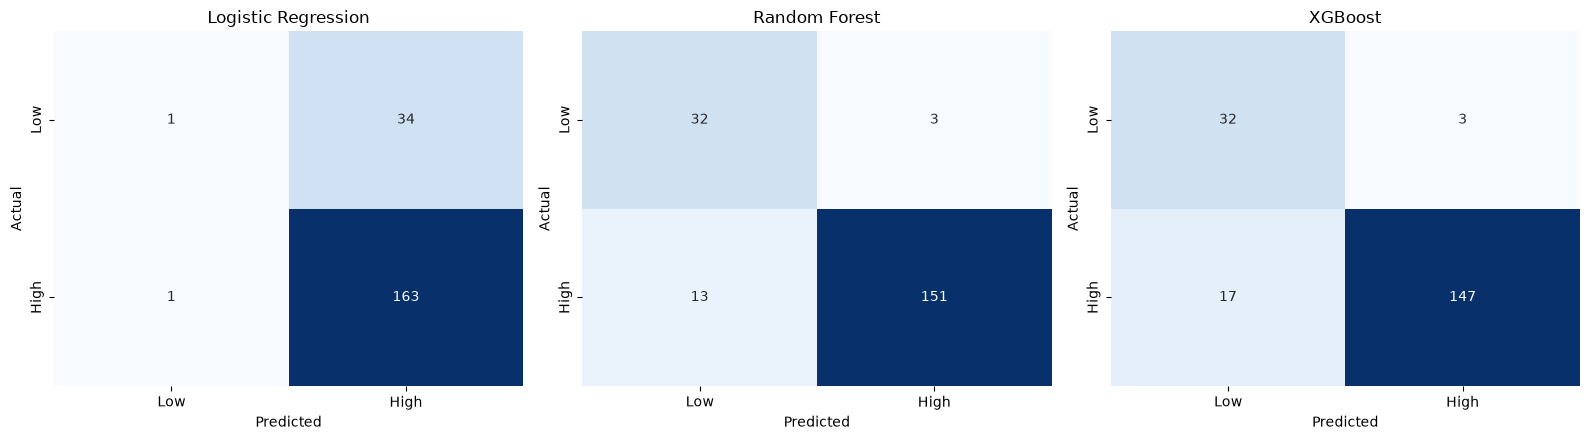

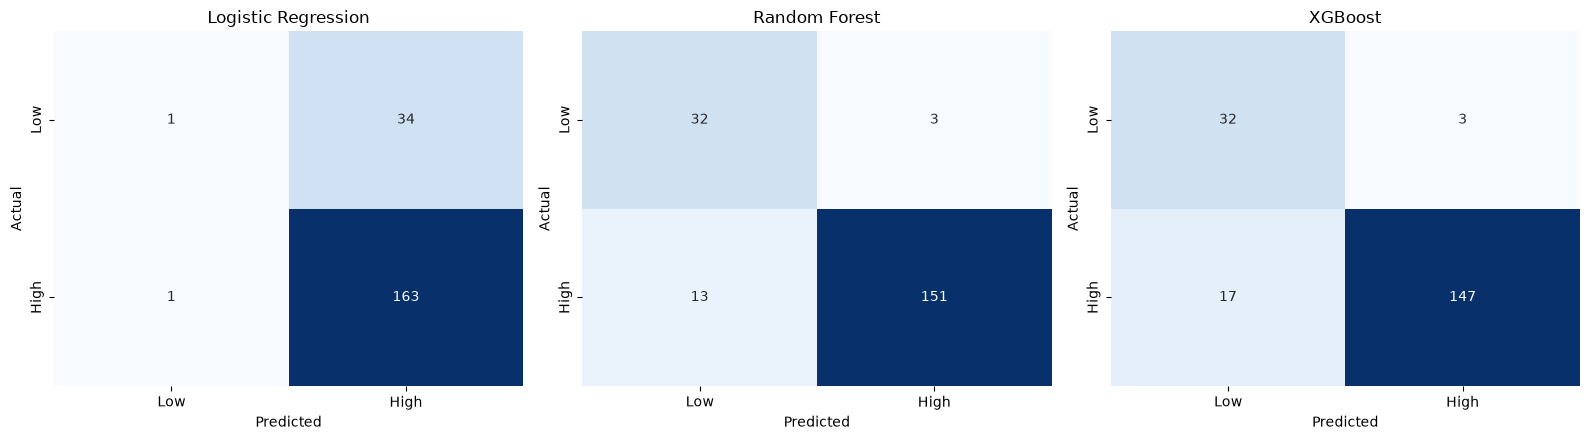

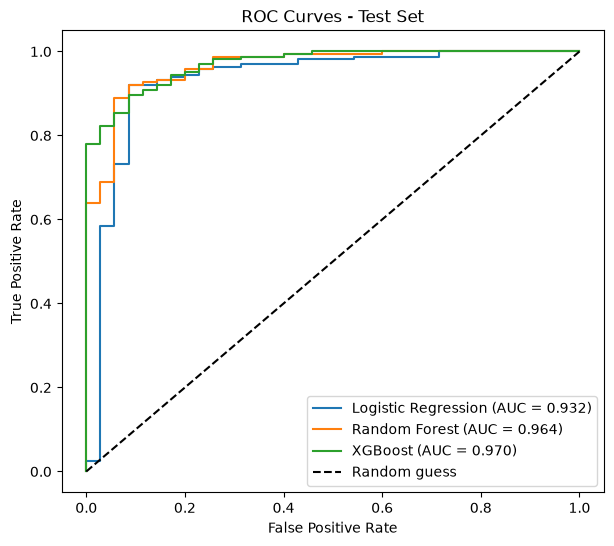

In [28]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, trained.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# After the classification report we have to do confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, trained.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# After the confusion matrix we have to do  bcz this will help us to compare the models on their ability to distunguish low risk vs high risk
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

for name, model in trained.items():

    if name == "Logistic Regression":
        prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, prob)

    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Test Set")
plt.legend()
plt.show()

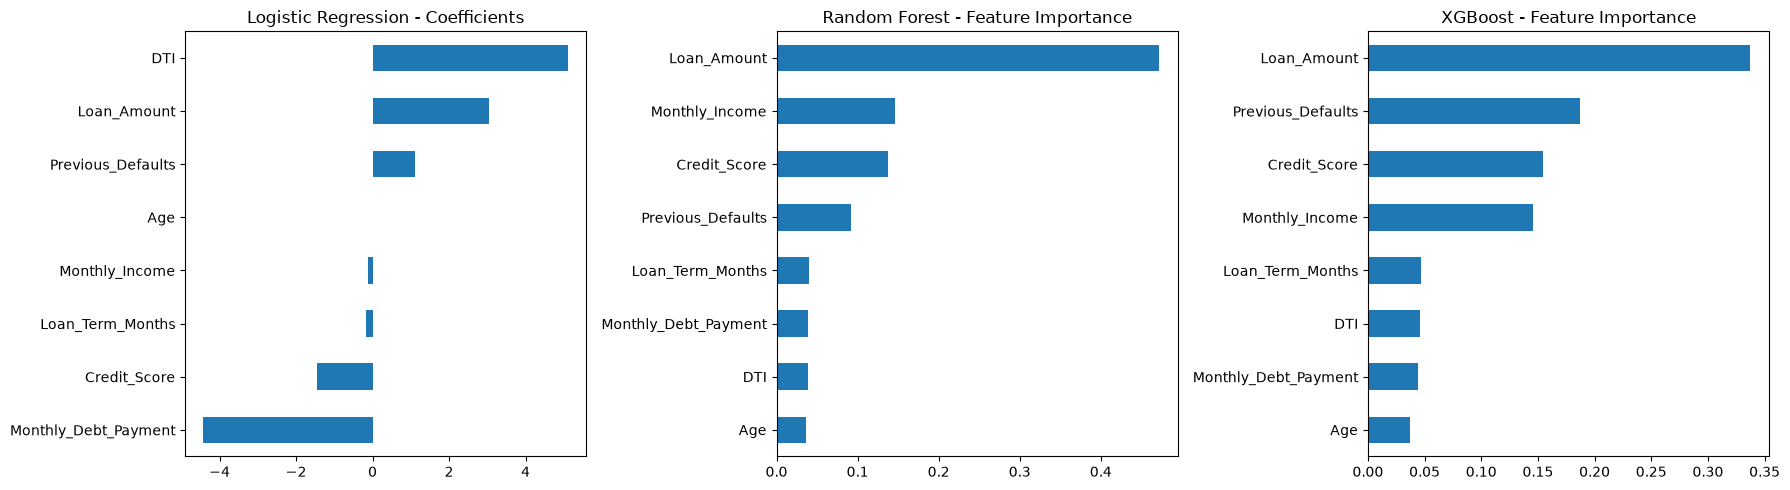

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pd.Series(
    trained["Logistic Regression"].coef_[0],
    index=features
).sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression - Coefficients")
pd.Series(
    trained["Random Forest"].feature_importances_,
    index=features
).sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("Random Forest - Feature Importance")
pd.Series(
    trained["XGBoost"].feature_importances_,
    index=features
).sort_values().plot(
    kind="barh",
    ax=axes[2]
)
axes[2].set_title("XGBoost - Feature Importance")
plt.tight_layout()
plt.show()

In [30]:
import joblib
import os

# Create model folder
os.makedirs("../model", exist_ok=True)

# Save the final Random Forest model
joblib.dump(
    trained["Random Forest"],
    "../model/loan_risk_random_forest.pkl"
)

# Save the imputer
joblib.dump(
    imputer,
    "../model/loan_risk_imputer.pkl"
)

# Save feature names
joblib.dump(
    features,
    "../model/loan_risk_features.pkl"
)

print("Random Forest model and preprocessing files saved successfully.")

Random Forest model and preprocessing files saved successfully.
